In [1]:
#Jonathan Borowsky
#Grabe lab
#4/9/26

#plots for collaboration with Rutter lab

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.analysis import dihedrals
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
from MDAnalysis.analysis.dssp import DSSP

In [3]:
#                           GET RESIDUE INFORMATION FOR PYMOL INSPECTION

def residues(whichprotein, whichresidue):

    if whichprotein == "aac1":
        offset = 1
    elif whichprotein == "ucp1":
        offset = 9
    else:
        print(f"invalid protein {whichprotein}")
        return 0

    toppath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/input/topol.top"
    trjpath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/traj_comp.part0001-centered.xtc"
    u = mda.Universe(toppath, trjpath, topology_format='ITP')

    n_frames = len(u.trajectory)
    n_residues = len(u.select_atoms(f"resname {whichresidue.upper()}").residues)

    #print(u.select_atoms(f"resname {whichresidue.upper()}").residues)
    resseqs = [r.resid for r in u.select_atoms(f"resname {whichresidue.upper()}").residues]

    return resseqs

In [77]:
def load_process(analysis_method, resn):

    #this path actually also contains serine rotamers
    inputpath = "/home/jonathan/Documents/grabelab/rutter-lab-collaboration/thr_rotamers_solvation/resi_data"

    servers = ["wynton", "degrabo"]
    proteins = ["ucp1", "aac1"]

    helix_solv_rotamers_bothproteins = []
    resseqs_both = []
    prots_both = []

    #loop over servers, proteins, and parallel runs
    for protein in proteins:

        print("---------------------------------------------: " +protein)
        rotamer_data = []
        hbond_data = []
        helix_data = []
        framerates = []

        resseqs = residues(protein, resn)
        resseqs_both += resseqs
        prots_both += [protein for _ in resseqs]

        for server in servers:    
            for run in range(1,5):
                #not all servers have the same number of parallel simulations
                if run > 2 and server == "degrabo": continue

                if run > 2:
                    framerate = 2
                else:
                    framerate = 1

                for seg in range(1,20):
                    #load data if it exists
                    rotamer_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-rotamers.npy"
                    hbond_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-hbonds.npy"
                    secstr_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-secstr.npy"

                    if os.path.exists(rotamer_file) and os.path.exists(hbond_file) and os.path.exists(secstr_file):
                        rotamer_data.append(np.load(rotamer_file))#[:,::framerate])
                        hbond_data.append(np.load(hbond_file))#[:,::framerate])
                        helix_data.append(np.load(secstr_file))#[:,::framerate])
                        framerates.append(framerate*np.ones(rotamer_data[-1].shape[1]))

        #residue level variation is much larger than simulation-level variation, 
        # so standard deviations and errors are computed across residues rather than simulations
        rotamer_data = np.concatenate(rotamer_data, axis = 1)
        hbond_data = np.concatenate(hbond_data, axis = 1)
        helix_data = np.concatenate(helix_data, axis = 1)
        framerates = np.concatenate(framerates, axis = 0)

        state_rotamers_byresi = analysis_method(len(resseqs), rotamer_data, hbond_data, helix_data)

        helix_solv_rotamers_bothproteins.append(state_rotamers_byresi)

        printresseqs = True
        if printresseqs:
            helixdict = {0:"loop", 1:"mixed", 2:"helix"}
            hbonddict = {0:"buried", 1:"interfacial", 2:"solvated"}

            #1st axis is helicity, second is solvation
            rsq_by_category = [[[] for _ in range(3)] for _ in range(3)]

            for r, rsq in zip(state_rotamers_byresi, resseqs):
                rsq_by_category[int(r[0])][int(r[1])].append(rsq)
                #print(f"{rsq}: {helixdict[r[0]]}, {hbonddict[r[1]]}")

            for i in range(3):
                for j in range(3):
                    header = f"{helixdict[i]}, {hbonddict[j]}: resi "
                    rsq_str = "+".join([str(r) for r in rsq_by_category[i][j]])
                    print(header+rsq_str)


    helix_solv_rotamers_bothproteins = np.concatenate(helix_solv_rotamers_bothproteins)

    return helix_solv_rotamers_bothproteins, resseqs_both, prots_both



In [92]:
#each element of rotamers is 0 = 180 degrees, 1 = -60 degrees, 2 = 60 degrees
#each element of hbonds is # hydrogen bonds to water
#each element of secstr is 0 if loop, 1 if helical (the protein contains no beta sheets)

def rotamer_hbond_secstr(n_residues, rotamers, hbonds, secstr):

    #thresholds to match quantitative deltadeltaG analysis
    helicity_helical_thresh = 0.75
    helicity_loop_thresh = 0.1

    hbond_dry_thresh = 0.05
    hbond_wet_thresh = 2/3

    rotamer_secstr_hbond = np.zeros((n_residues, 5)) #second index: helicity_state, hbond_state, probability of adopting each rotamer
    for nr in range(n_residues):

        #helicity state
        helical_fraction = np.sum(secstr[nr]) / len(secstr[nr])
        if helical_fraction >= helicity_helical_thresh:
            helicity_state = 2  # helical
        elif helical_fraction <= helicity_loop_thresh:
            helicity_state = 0  # loop
        else:
            helicity_state = 1  # intermediate

        #hbond state
        hbond_fraction = np.sum(hbonds[nr]) / len(hbonds[nr])
        if hbond_fraction >= hbond_wet_thresh:
            hbond_state = 2  # solvated
        elif hbond_fraction <= hbond_dry_thresh:
            hbond_state = 0  # buried
        else:
            hbond_state = 1  # interfacial

        #rotamer probabilities
        rotamer_counts = np.sum(np.eye(3)[rotamers[nr]], axis=0)
        rotamer_probs = rotamer_counts/len(rotamers[nr])

        #add to array
        rotamer_secstr_hbond[nr, 0] = helicity_state
        rotamer_secstr_hbond[nr, 1] = hbond_state
        rotamer_secstr_hbond[nr,2:5] = rotamer_probs

    return rotamer_secstr_hbond


#load_process(rotamer_hbond_secstr, resn)

In [101]:
resn = "ser"

data, resseqs_all, prots_all = load_process(rotamer_hbond_secstr, resn)

---------------------------------------------: ucp1


/home/jonathan/anaconda3/envs/serpents/lib/python3.11/site-packages/MDAnalysis/topology/ITPParser.py:646: DeprecationWarning: The elements attribute has been populated by guessing elements from atom types. This behaviour has been temporarily added to the ITPParser as we transition to the new guessing API. This behavior will be removed in release 3.0. Please see issue #4698 for more information. 
  warnings.warn(


loop, buried: resi 
loop, interfacial: resi 144
loop, solvated: resi 49+50+111+114+249+273+298
mixed, buried: resi 
mixed, interfacial: resi 89
mixed, solvated: resi 75+296
helix, buried: resi 18+217+279
helix, interfacial: resi 87+229
helix, solvated: resi 86+183+230+242
---------------------------------------------: aac1
loop, buried: resi 
loop, interfacial: resi 68+179+275
loop, solvated: resi 1+6+45+212
mixed, buried: resi 
mixed, interfacial: resi 241
mixed, solvated: resi 41
helix, buried: resi 
helix, interfacial: resi 118+126+227
helix, solvated: resi 21+166


In [102]:
def process_rotamers_for_bargraph(helix_solv_rotamers, resseqs_all, prots_all, helicesonly=False, mergepm60=False):
    #buried, solvated
    if helicesonly:
        data_by_class = [[],[]]
        prot_rsq_by_class = [[],[]]
    else:
        data_by_class = [[],[],[],[]]
        prot_rsq_by_class = [[],[],[],[]]

    for r, resseq, prot in zip(helix_solv_rotamers, resseqs_all, prots_all):
        if prot == "aac1" and resseq == 253:
            continue

        if r[0] == 2: #helices
            if r[1] == 0: #buried
                data_by_class[0].append(r[2:])
                prot_rsq_by_class[0].append(f"{prot} {resseq}")
            elif r[1] == 2: #solvated
                data_by_class[1].append(r[2:])
                prot_rsq_by_class[1].append(f"{prot} {resseq}")

        elif not helicesonly and r[0] == 0: #loops if applicable
            if r[1] == 0: #buried
                data_by_class[2].append(r[2:])
                prot_rsq_by_class[2].append(f"{prot} {resseq}")
            elif r[1] == 2: #solvated
                data_by_class[3].append(r[2:])
                prot_rsq_by_class[3].append(f"{prot} {resseq}")


    #number of residues in each class
    n = [len(d) for d in data_by_class]

    #stack lists of 1d arrays into 2d arrays
    for i in range(len(data_by_class)):
        if len(data_by_class[i]) > 0:
            data_by_class[i] = np.stack(data_by_class[i])
        #provide dummy values if no rotamers were found in a given state so that the code below runs
        else:
            print(f"no frames in class {i}")
            data_by_class[i] = np.zeros((3,3)) 

    #merge plus and minus 60 degree rotamer counts
    if mergepm60:
        for i in range(len(data_by_class)):
            data_by_class[i] = np.stack((data_by_class[i][:,0], data_by_class[i][:,1]+data_by_class[i][:,2]))
    
    #mean and standard deviations of rotamer (group) frequencies in each class
    means = np.stack([np.mean(d, axis=1) for d in data_by_class])
    stdevs = np.stack([np.std(d, axis=1) for d in data_by_class])
    #the standard deviations for the 180 and +- 60 rotamer groups being equal is normal when there are only two rotamer classes

    return n, means, stdevs, data_by_class, prot_rsq_by_class

n, means, stdevs, data_by_class, prot_rsq_by_class = process_rotamers_for_bargraph(data, resseqs_all, prots_all, helicesonly=False, mergepm60=True)
print(n, means, stdevs)

no frames in class 2
[3, 6, 0, 11] [[0.01265738 0.98734262]
 [0.5711904  0.4288096 ]
 [0.         0.        ]
 [0.43684335 0.56315665]] [[0.00484659 0.00484659]
 [0.29167629 0.29167629]
 [0.         0.        ]
 [0.26286555 0.26286555]]


In [107]:
#data_by_class

In [104]:
for r, d in zip(prot_rsq_by_class[3], data_by_class[3][0]):
    print(f"{r}: {d:.2f}") 

ucp1 49: 0.55
ucp1 50: 0.30
ucp1 111: 0.24
ucp1 114: 0.34
ucp1 249: 0.03
ucp1 273: 0.98
ucp1 298: 0.16
aac1 1: 0.40
aac1 6: 0.40
aac1 45: 0.65
aac1 212: 0.74


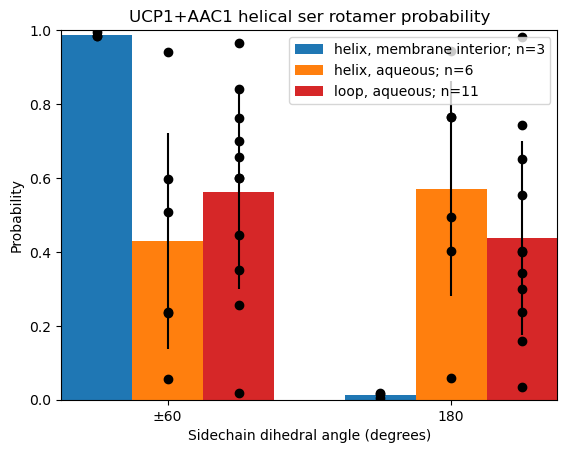

In [105]:
def plot_rotamers_4_sites(mean_std_rotamer_freqs, n_resis_by_site, resi_data, protein, resn):
    bar_width = 0.25
    gap_width = 0.25

    x = -bar_width/2 #bar center x coordinate
    
    site_inds = [0,1,2,3]
    site_names = ["helix, membrane interior", "helix, aqueous", "loop, membrane interior", "loop, aqueous"]
    site_names_occupied = []
    n_resis_by_site_occupied = []
    rotamer_inds = [1,0]

    xtick_pos = []

    for rotamer in rotamer_inds:
        xs0 = x
        for site, nrbs, rdata, sn, color in zip(site_inds, n_resis_by_site, resi_data, site_names, ["C0","C1","C2","C3"]):
            if nrbs > 0:
                #mean and standard deviation rotamer probability
                plt.bar((x), (mean_std_rotamer_freqs[0,site,rotamer]), yerr=(mean_std_rotamer_freqs[1,site,rotamer]), width=bar_width, color = color)
                
                #rotamer probability by residue
                for rd in rdata[rotamer]:
                    plt.scatter(x,rd, color = "black", label = "_nolegend_")
                
                x += bar_width
                
                #include names of all occupied sites in legend
                if sn not in site_names_occupied:
                    site_names_occupied.append(sn)
                    n_resis_by_site_occupied.append(nrbs)

        xtick_pos.append((x - bar_width + xs0)/2) #center x tick for each rotamer under the bars for that rotamer

        x += gap_width

    plt.xticks(xtick_pos, ('±60', '180'))
    #offset = 1.5
    plt.xlim(-bar_width, x - gap_width - bar_width/2)
    plt.ylim(0,1)

    plt.ylabel("Probability")
    plt.xlabel("Sidechain dihedral angle (degrees)")
    plt.legend([f"{name}; n={num}" for name, num in zip(site_names_occupied, n_resis_by_site_occupied)])

    plt.title(f"{protein.upper()} helical {resn} rotamer probability")

    plt.savefig(f"figures/{protein}-{resn}-all-pm60-rotamers.png", dpi=600)

    plt.show()

mean_std_rotamer_freqs = np.stack((means, stdevs))
plot_rotamers_4_sites(mean_std_rotamer_freqs, n, data_by_class, "UCP1+AAC1", resn)

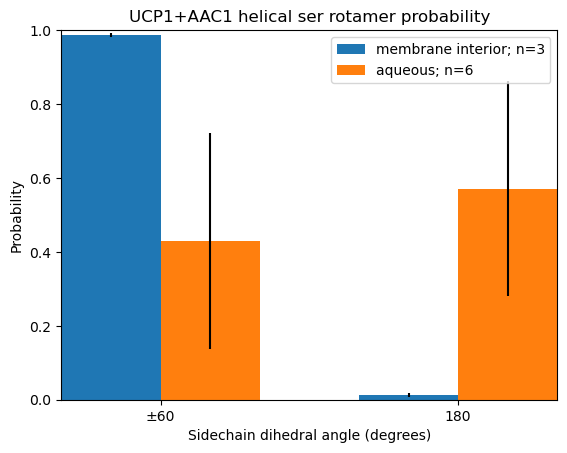

In [106]:
def plot_rotamers_2_sites(mean_std_rotamer_freqs, n_resis_by_site, protein, resn):
    bar_width = 0.25
    gap_width = 0.25

    x = -bar_width/2
    
    site_inds = [0,1]
    rotamer_inds = [1,0]

    for rotamer in rotamer_inds:
        for site, color in zip(site_inds, ["C0","C1"]):

            plt.bar((x), (mean_std_rotamer_freqs[0,site,rotamer]), yerr=(mean_std_rotamer_freqs[1,site,rotamer]), width=bar_width, color = color)

            x += bar_width
        x += gap_width

    plt.xticks([0,0.75], ('±60', '180'))
    #offset = 1.5
    plt.xlim(-bar_width, 4*bar_width)
    plt.ylim(0,1)

    plt.ylabel("Probability")
    plt.xlabel("Sidechain dihedral angle (degrees)")
    plt.legend([f"membrane interior; n={n_resis_by_site[site_inds[0]]}", f"aqueous; n={n_resis_by_site[site_inds[1]]}"]) #, f"loop (aqueous); n={n_resis_by_site[site_inds[2]]}"])

    plt.title(f"{protein.upper()} helical {resn} rotamer probability")

    plt.savefig(f"figures/{protein}-{resn}-helix-pm60-rotamers.png", dpi=600)

    plt.show()

mean_std_rotamer_freqs = np.stack((means, stdevs))
plot_rotamers_2_sites(mean_std_rotamer_freqs, n, "UCP1+AAC1", resn)

In [ ]:
# def rotamer_stats(helix_solv_rotamers, sitetypes, rotamertypes):
    
#     if sitetypes == "all":
#         helix_types = [0,2]
#         solv_types = [0,2]
#     elif sitetypes == "helixonly":
#         helix_types = [2]
#         solv_types = [0,2]

#     if rotamertypes == "all":
#         rotamergroups = [[0],[1],[2]]
#     elif rotamertypes == "180_pm60":
#         rotamergroups = [[0],[1,2]]

#     data_by_class = [[[] for b in range(len(rotamergroups))] for a in range(len(helix_types)*len(helix_types))]

#     print(data_by_class)

#     for r in helix_solv_rotamers:
#         data_by_class[r[]]

In [ ]:
    #     dG_all.append(dG)
    #     hbond_t_frac_all.append(hbond_t_frac)
    #     resseq_all += resseqs
    #     prot_all += [protein for x in range(len(resseqs))]

    #     # dG_dry, dG_wet, dG_interfacial = analysis_method(rotamer_data, hbond_data, helix_data)
    #     # dG_dry_all.append(dG_dry)
    #     # dG_wet_all.append(dG_wet)
    #     # dG_interfacial_all.append(dG_interfacial)

    # # print(list(dG_wet_all))
    # # print(list(dG_dry_all))
    # # print(list(dG_interfacial_all))

    # # dG_dry_all = np.concatenate(dG_dry_all)
    # # dG_wet_all = np.concatenate(dG_wet_all)
    # # dG_interfacial_all = np.concatenate(dG_interfacial_all)
    # print(dG_all)
    # print(hbond_t_frac_all)

    #     dG, hbond_t_frac, resseqs = analysis_method(rotamer_data, hbond_data, helix_data, resseqs)

    #     print(dG)
    #     print(hbond_t_frac)



    # dG_all = np.concatenate(dG_all)
    # hbond_t_frac_all = np.concatenate(hbond_t_frac_all)

    # return dG_all, hbond_t_frac_all, prot_all, resseq_all

    # dG_dry_all = []
    # dG_wet_all = []
    # dG_interfacial_all = []
    # dG_all = []
    # hbond_t_frac_all = []

    # resseq_all = []
    # prot_all = []

        #for x,y,z in zip(secstr[nr], rotamers[nr], hbonds[nr]):
        #    rotamer_hbonds[nr,y,z]+=1